# Setup

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import random
import pandas as pd
train=pd.read_csv("../data/case1/train1.csv")
test=pd.read_csv("../data/case1/test1.csv")

for df in (train, test):
    df["n"] = df["speed_rpm"] / 1000
    df["Q"] = df["flow_m3_h"]
    df["P"] = df["power_w"]

train=train[["n", "Q","P"]]
test=test[["n", "Q","P"]]

In [18]:
def make_features(df):
    features = pd.DataFrame()

    for i in range(4):
        for j in range(4):
            if i == 0 and j == 0:
                continue
            column_name = "n" + str(i) + "Q" + str(j)
            features[column_name] = df["n"] ** i * df["Q"] ** j
    return features

X_train = make_features(train)
y_train = train["P"]

X_test = make_features(test)
y_test = test["P"]


# Backward selection using MSE

In [6]:
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LinearRegression

lrr = LinearRegression()
sfs = SequentialFeatureSelector(lrr, n_features_to_select='auto', direction="backward", tol=-0.001)
sfs.fit(X_train, y_train)

,estimator,LinearRegression()
,n_features_to_select,'auto'
,tol,-0.001
,direction,'backward'
,scoring,None
,cv,5
,n_jobs,None
,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None


In [7]:
selected = X_train.columns[sfs.get_support()]
print(list(selected))

['n1Q1', 'n1Q2', 'n2Q2', 'n2Q3', 'n3Q0']


In [8]:
lrr.fit(X_train[selected], y_train)
print(dict(zip(selected, lrr.coef_)), lrr.intercept_)

{'n1Q1': np.float64(8.319655673224737), 'n1Q2': np.float64(-0.4162002759569882), 'n2Q2': np.float64(0.10515059152389981), 'n2Q3': np.float64(-0.0006894757331210999), 'n3Q0': np.float64(8.830981369348637)} -7.717399353834139


In [9]:
from sklearn.metrics import r2_score
lrr_final = LinearRegression().fit(X_train[selected],y_train)

y_pred=lrr_final.predict(X_test[selected])
print("R² (Q):", r2_score(y_test, y_pred))

R² (Q): 0.9989428447246667


# Forward selection with MSE

In [22]:
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LinearRegression

lrr = LinearRegression()
sfs = SequentialFeatureSelector(lrr, n_features_to_select='auto', direction="forward", tol=0.0001)
sfs.fit(X_train, y_train)

,estimator,LinearRegression()
,n_features_to_select,'auto'
,tol,0.0001
,direction,'forward'
,scoring,None
,cv,5
,n_jobs,None
,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None


In [23]:
selected = X_train.columns[sfs.get_support()]
print(list(selected))

['n0Q3', 'n2Q1', 'n3Q0']


In [24]:
lrr.fit(X_train[selected], y_train)
print(dict(zip(selected, lrr.coef_)), lrr.intercept_)

{'n0Q3': np.float64(-0.011068933871795215), 'n2Q1': np.float64(2.161853837435272), 'n3Q0': np.float64(7.901797356187623)} 41.12900747389631


In [25]:
from sklearn.metrics import r2_score
lrr_final = LinearRegression().fit(X_train[selected],y_train)

y_pred=lrr_final.predict(X_test[selected])
print("R² (Q):", r2_score(y_test, y_pred))

R² (Q): 0.9995873168512341


# Forward selection using BIC

Selected: ['n3Q0', 'n2Q1', 'n0Q3', 'n1Q2']  BIC: 2273.306938325188
R² (test): 0.9996292902531838


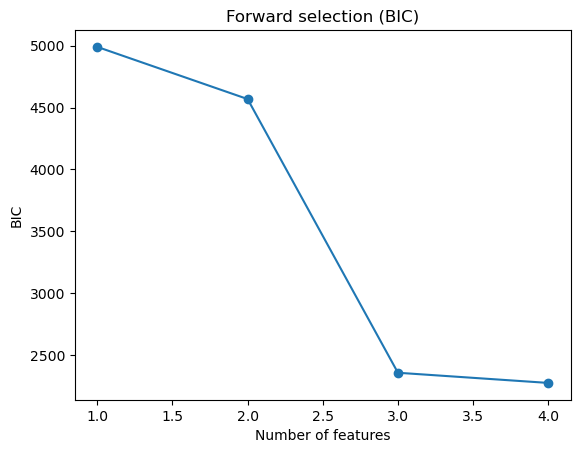

In [32]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
import numpy as np

def bic(X, y):
    model = LinearRegression().fit(X, y)
    rss = np.sum((y - model.predict(X)) ** 2)
    n = len(y)
    k = X.shape[1] + 1          # +1 for the intercept
    return n * np.log(rss / n) + k * np.log(n) # ignoring constant n*log(2\pi)+n

def forward_bic(X, y):
    n = len(y)
    selected= []
    remaining = list(X.columns)
    history = []
    while remaining:
        scores = {f: bic(X[selected + [f]], y) for f in remaining}
        best = None
        for f in scores:
            if best is None or scores[f] < scores[best]:
                best = f
        if len(history) > 0 and scores[best] >= history[-1]:
            break
        selected.append(best)
        remaining.remove(best)
        history.append(scores[best])
    return selected, history

selected, history = forward_bic(X_train, y_train)
print("Selected:", selected, " BIC:", history[-1])

model = LinearRegression().fit(X_train[selected], y_train)
print("R² (test):", r2_score(y_test, model.predict(X_test[selected])))

plt.plot(range(1, len(history) + 1), history, marker="o")
plt.xlabel("Number of features"); plt.ylabel("BIC"); plt.title("Forward selection (BIC)")
plt.show()

Selected: ['n0Q1', 'n1Q1', 'n1Q2', 'n2Q2', 'n2Q3', 'n3Q0', 'n3Q1', 'n3Q2', 'n3Q3']  BIC: 2300.5155216565663
R² (test): 0.9996191252089163


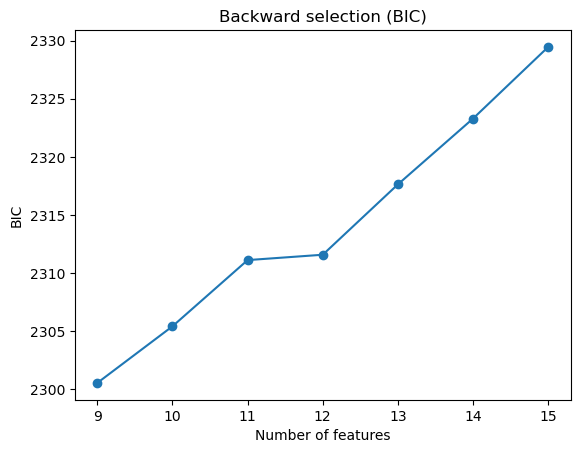

In [ ]:
def backward_bic(X, y):
    selected = list(X.columns)
    history = [bic(X[selected], y)]
    while len(selected) > 1: 
        scores = {f: bic(X[[c for c in selected if c != f]], y) for f in selected}
        best = None
        for f in scores:
            if best is None or scores[f] < scores[best]:
                best = f
        if scores[best] >= history[-1]:
            break
        selected.remove(best)
        history.append(scores[best])
    return selected, history

selected_bwd, history_bwd = backward_bic(X_train, y_train)
print("Selected:", selected_bwd, " BIC:", history_bwd[-1])

model_bwd = LinearRegression().fit(X_train[selected_bwd], y_train)
print("R² (test):", r2_score(y_test, model_bwd.predict(X_test[selected_bwd])))

p = X_train.shape[1]
plt.plot(range(p, p - len(history_bwd), -1), history_bwd, marker="o")
plt.xlabel("Number of features"); plt.ylabel("BIC"); plt.title("Backward selection (BIC)")
plt.show()